In [6]:
#file imports used
from PIL import Image
from bit_operators import BitFeederString, BitSaver
import os

In [7]:
#open a bmp and get its size
message="./dad.jpeg"
cover="./stego.bmp"
filesize = os.path.getsize(message)
number_of_bits = 1
x = Image.open(cover)
pic_size = x.size
num_of_pixels = x.size[0]*x.size[1]
available_bytes=(num_of_pixels*(number_of_bits*3))/8
print("Filesize="+str(filesize)+"\nCapacity="+str(int(available_bytes)))
if filesize > available_bytes:
    print("This is not going to work.")

Filesize=107413
Capacity=921600


In [8]:
bfeed = BitFeederString(message)
length = bfeed.get_length()
length

859304

In [9]:
#HOW TO CHOOSE CORRECT LEVEL
byte_string = '11111111'
mybit = '0'
level=5
byte_string = byte_string[:level-1]+mybit+byte_string[level:]
byte_string

'11110111'

In [10]:
#Makes sure we have an 8 bit byte from int
def byte_maker(color):
    return f'{color:08b}'
#returns an int from byte bin string
def int_maker(color):
    return int(color, 2)
#encodes however many bits specified
def encoder(cover,message,level=8):
    cover = cover[:level-1]+message+cover[level:]
    return cover

#PIXELS ENCODED
for i in range(pic_size[0]):
    for j in range(pic_size[1]):
        color = x.getpixel((i,j))
        modified = []
        #print("OG"+str(color))
        for RGB in range(len(color)):
                input = color[RGB]
                #print(str(input))
                cover = byte_maker(input)
                #print(cover)
                message = bfeed.get_bits(1)
                #print(message)
                encoded = encoder(cover,message)
                #print(encoded)
                output = int(encoded, 2)
                #print(output)
                modified.append(output)
        x.putpixel( (i , j), (modified[0], modified[1], modified[2], 255))
        #print("MOD"+str(x.getpixel((i,j))))
        if bfeed.finished == True:
            break

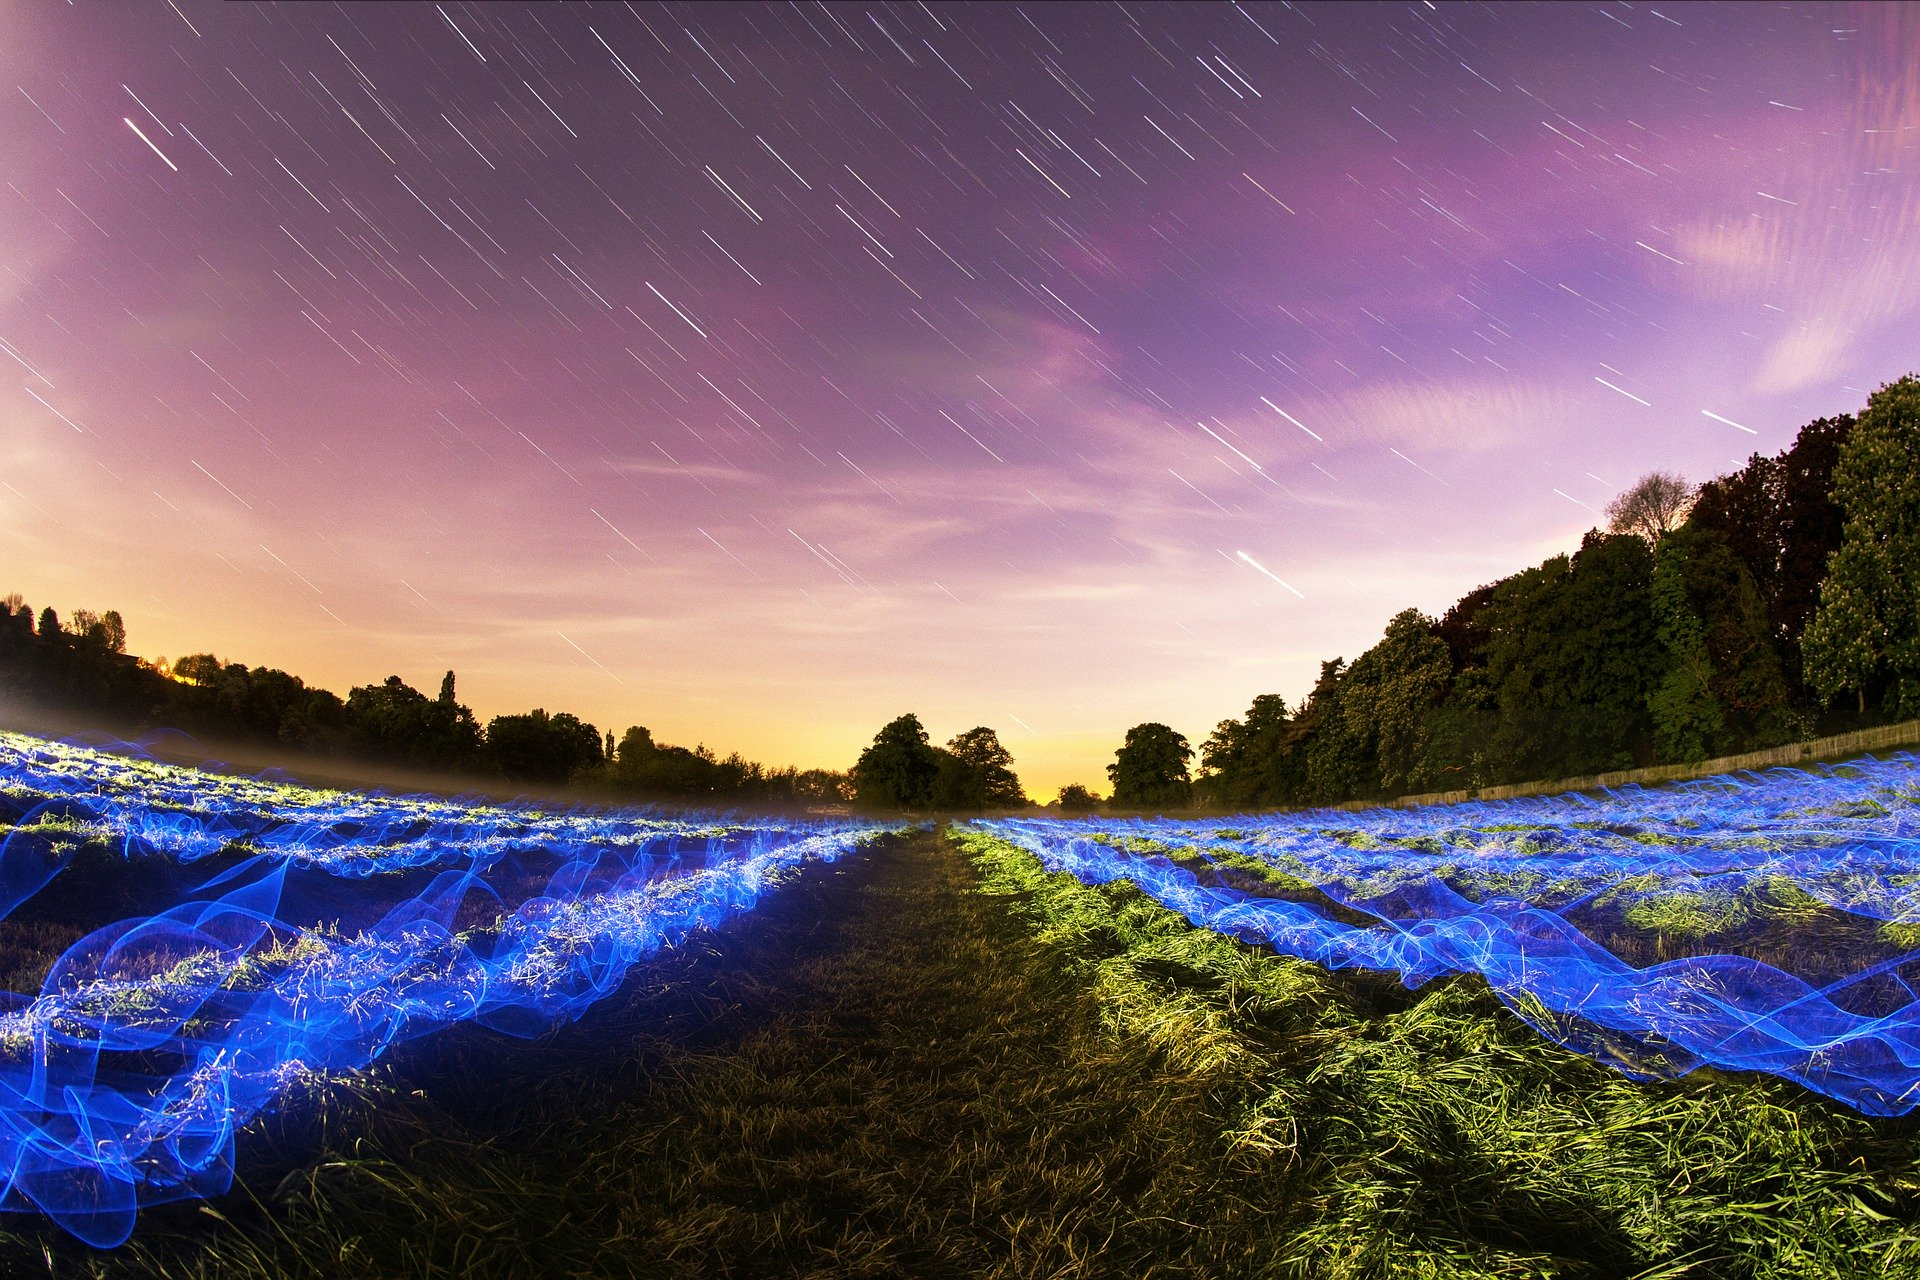

In [11]:
x

In [12]:
x.save("This_is_encoded.bmp", format="BMP")

In [13]:
x = Image.open("This_is_encoded.bmp")
bs = BitSaver(file_length=len(bfeed.bytes)*8)

In [14]:
def decoder(cover,level=8):
    return cover[level-1:level]

index = 0
finish = bfeed.get_length()
for i in range(pic_size[0]):
    for j in range(pic_size[1]): 
        color = x.getpixel((i,j))
        for RGB in range(len(color)):
            if index < finish:
                output=byte_maker(color[RGB])
                #print(output)
                bit = decoder(output)
                #print(bit)
                bs.add_bits(bit)
                index += 1
                #print(str(index)+ " " + str(bfeed.get_length()))
           

In [15]:
bs.save_file("output.jpg")